# Ensemble and Neural Network Comparison — AI4I Predictive Maintenance Analytics

I compare an MLP neural network, equal soft voting, fixed weighted soft voting, and stacking with the baseline classifiers.

I use the feature set selected in the baseline stage, the same training/validation assignments, and the saved training CV folds. I reuse verified baseline reference scores, fit the new candidates, and calculate the results without assuming an ensemble will win.

I also assess an exploratory version of H3, compare sigmoid calibration with the selected uncalibrated model, and examine validation threshold tradeoffs.

**Inputs:** the cleaned data, saved split files, and reports/model metadata from `06_model_training_baseline.ipynb`.  
**Outputs:** reports in `reports/ensemble_comparison/`, charts in `visuals/ensemble_comparison/`, and provisional models in `models/ensemble_comparison/`.

Final-test observations remain unscored. They appeared in early EDA, so later evaluation retains that limitation.


## 1. Set up the comparison

I use scikit-learn's MLP for this tabular problem. Rows are not treated as sequences from a machine's lifetime.

Voting combines base-model scores. Stacking learns a logistic meta-model from out-of-fold base predictions. Each base learner has its own preprocessing pipeline, including within stacking's inner folds.

References: [soft voting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html), [stacking](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html), [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).

This notebook fits nested models and may take several minutes. I limit BLAS threads for the small neural-network matrices while allowing Random Forest to parallelize its trees.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    VotingClassifier, StackingClassifier,
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    average_precision_score, brier_score_loss, classification_report,
    ConfusionMatrixDisplay, f1_score, log_loss, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
ALPHA = 0.05
H3_BOOTSTRAP_REPEATS = 3000
VOTING_WEIGHTS = [2, 2, 1]  # RF, GB, MLP; fixed before inspecting new validation results
DEFAULT_THRESHOLD = 0.5
RECALL_SCENARIOS = [0.80, 0.90, 0.95]
RAW_NUMERIC = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
]
RAW_FEATURES = RAW_NUMERIC + ["Type"]
ENGINEERED_FEATURES = ["Temp_diff", "Torque_RPM_ratio"]
EXCLUDED_COLUMNS = {"UDI", "Product ID", "Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"}
plt.rcParams["figure.figsize"] = (9, 5)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

fit_warning_rows = []

def recorded_fit(candidate_id, phase, operation):
    print(f"Starting {phase}: {candidate_id}", flush=True)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
        warnings.simplefilter("always")
        result = operation()
    for warning in caught:
        fit_warning_rows.append({
            "candidate": candidate_id, "phase": phase,
            "warning_class": warning.category.__name__,
            "message": str(warning.message),
        })
    print(f"Completed {phase}: {candidate_id} ({time.perf_counter() - started:.1f}s)", flush=True)
    return result

def positive_scores(model, features):
    position = int(np.flatnonzero(model.classes_ == 1)[0])
    scores = model.predict_proba(features)[:, position]
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Expected finite scores within [0, 1].")
    return scores

def metrics_at_threshold(labels, scores, threshold):
    actual = np.asarray(labels)
    predicted = (np.asarray(scores) >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "average_precision": float(average_precision_score(actual, scores)),
        "roc_auc": float(roc_auc_score(actual, scores)),
        "precision": float(precision_score(actual, predicted, zero_division=0)),
        "recall": float(recall_score(actual, predicted, zero_division=0)),
        "f1": float(f1_score(actual, predicted, zero_division=0)),
        "false_negatives": int(((actual == 1) & (predicted == 0)).sum()),
        "false_positives": int(((actual == 0) & (predicted == 1)).sum()),
    }

print(f"Python: {platform.python_version()}; scikit-learn: {sklearn.__version__}")


Python: 3.13.5; scikit-learn: 1.6.1


## 2. Verify inputs and the baseline sample

I verify checksums recorded in the baseline metadata, package compatibility, observation assignments, and baseline fold membership. I align cached validation predictions by UDI rather than assuming their row order.

The reference models are evaluated using exactly the baseline-selected feature set. I retain the provisional baseline winner even if its model family differs from the initial Random Forest reference.


In [2]:
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "models" / "baseline" / "model_metadata.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run 06_model_training_baseline.ipynb inside this project first.")

input_paths = {
    "data": PROJECT_ROOT / "data/cleaned/ai4i2020_cleaned.csv",
    "split": PROJECT_ROOT / "reports/smote/split_manifest.csv",
    "smote_settings": PROJECT_ROOT / "reports/smote/experiment_settings.json",
    "baseline_settings": PROJECT_ROOT / "reports/baseline/experiment_settings.json",
    "baseline_cv_results": PROJECT_ROOT / "reports/baseline/cross_validation_results.csv",
    "baseline_cv_folds": PROJECT_ROOT / "reports/baseline/cross_validation_folds.csv",
    "baseline_fold_manifest": PROJECT_ROOT / "reports/baseline/training_cv_fold_manifest.csv",
    "baseline_validation": PROJECT_ROOT / "reports/baseline/validation_predictions.csv",
    "baseline_metadata": PROJECT_ROOT / "models/baseline/model_metadata.json",
    "baseline_schema": PROJECT_ROOT / "models/baseline/input_schema.json",
    "baseline_model": PROJECT_ROOT / "models/baseline/selected_baseline.joblib",
}
for path in input_paths.values():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.relative_to(PROJECT_ROOT)}. Rerun notebook 06.")
input_checksums = {name: sha256(path) for name, path in input_paths.items()}
baseline_metadata = json.loads(input_paths["baseline_metadata"].read_text(encoding="utf-8"))
baseline_schema = json.loads(input_paths["baseline_schema"].read_text(encoding="utf-8"))
baseline_settings = json.loads(input_paths["baseline_settings"].read_text(encoding="utf-8"))
if sklearn.__version__ != baseline_metadata["versions"]["scikit_learn"]:
    raise ValueError("The scikit-learn version changed. Rerun notebook 06 in this environment first.")
for key in ["data", "split", "smote_settings"]:
    path = input_paths[key]
    if input_checksums[key] != baseline_metadata["input_checksums"][path.name]:
        raise ValueError(f"Baseline input changed: {path.name}")

FEATURE_SET = baseline_schema["feature_set"]
if FEATURE_SET not in ["raw", "engineered"]:
    raise ValueError("Unexpected baseline feature set.")
MODEL_INPUT_COLUMNS = RAW_FEATURES + (ENGINEERED_FEATURES if FEATURE_SET == "engineered" else [])
if MODEL_INPUT_COLUMNS != baseline_schema["model_input_columns"]:
    raise ValueError("The baseline feature schema differs from the supported formulas.")

df = pd.read_csv(input_paths["data"])
manifest = pd.read_csv(input_paths["split"])
fold_manifest = pd.read_csv(input_paths["baseline_fold_manifest"])
baseline_cv = pd.read_csv(input_paths["baseline_cv_results"], index_col="candidate")
baseline_fold_scores = pd.read_csv(input_paths["baseline_cv_folds"])
cached_predictions = pd.read_csv(input_paths["baseline_validation"]).set_index("UDI")

required = ["UDI", "Machine failure", *RAW_FEATURES]
if not set(required).issubset(df.columns):
    raise ValueError("Required dataset columns are missing.")
if df[required].isna().any().any() or manifest.isna().any().any():
    raise ValueError("Required input fields must be complete.")
if df["UDI"].duplicated().any() or manifest["UDI"].duplicated().any():
    raise ValueError("UDI must be unique.")
if set(df["UDI"]) != set(manifest["UDI"]):
    raise ValueError("The split manifest must cover exactly the cleaned dataset.")
if set(manifest["split"]) != {"train", "validation", "final_test"}:
    raise ValueError("Unexpected split assignments.")

joined = df.merge(
    manifest.rename(columns={"Machine failure": "manifest_target"}),
    on="UDI", validate="one_to_one",
)
if not joined["Machine failure"].eq(joined["manifest_target"]).all():
    raise ValueError("Target labels differ between the dataset and split manifest.")
train_df = joined.loc[joined["split"].eq("train")].copy().reset_index(drop=True)
validation_df = joined.loc[joined["split"].eq("validation")].copy().reset_index(drop=True)
final_test_udi = set(joined.loc[joined["split"].eq("final_test"), "UDI"])
if not set(train_df["UDI"]).isdisjoint(final_test_udi | set(validation_df["UDI"])):
    raise ValueError("The saved split contains overlapping observations.")
if not set(validation_df["UDI"]).isdisjoint(final_test_udi):
    raise ValueError("Validation and final-test observations overlap.")

def prepare_features(frame):
    prepared = frame.loc[:, RAW_FEATURES].copy()
    if prepared.isna().any().any() or not prepared["Type"].isin(["L", "M", "H"]).all():
        raise ValueError("Invalid raw input values.")
    if not np.isfinite(prepared[RAW_NUMERIC].to_numpy(dtype=float)).all():
        raise ValueError("Numeric inputs must be finite.")
    if (prepared["Rotational speed [rpm]"] <= 0).any():
        raise ValueError("Rotational speed must be positive.")
    if FEATURE_SET == "engineered":
        prepared["Temp_diff"] = prepared["Process temperature [K]"] - prepared["Air temperature [K]"]
        prepared["Torque_RPM_ratio"] = prepared["Torque [Nm]"] / (prepared["Rotational speed [rpm]"] + 1)
    prepared = prepared.loc[:, MODEL_INPUT_COLUMNS]
    assert set(prepared.columns).isdisjoint(EXCLUDED_COLUMNS)
    return prepared

X_train = prepare_features(train_df)
X_validation = prepare_features(validation_df)
y_train = train_df["Machine failure"].astype(int)
y_validation = validation_df["Machine failure"].astype(int)
if not y_train.isin([0, 1]).all() or y_train.nunique() != 2 or y_validation.nunique() != 2:
    raise ValueError("Both binary classes must be present.")

if fold_manifest["UDI"].duplicated().any() or set(fold_manifest["UDI"]) != set(train_df["UDI"]):
    raise ValueError("The saved CV folds must cover exactly the training rows.")
aligned_folds = fold_manifest.set_index("UDI").loc[train_df["UDI"]]
if not np.array_equal(aligned_folds["Machine failure"], y_train):
    raise ValueError("CV fold targets differ from the training labels.")
fold_ids = aligned_folds["held_out_fold"].to_numpy()
expected_fold_ids = set(range(1, baseline_metadata["cv_splits"] + 1))
if set(fold_ids) != expected_fold_ids:
    raise ValueError("Unexpected fold IDs.")
cv_folds = [
    (np.flatnonzero(fold_ids != fold_id), np.flatnonzero(fold_ids == fold_id))
    for fold_id in sorted(expected_fold_ids)
]
for fit_indices, score_indices in cv_folds:
    if y_train.iloc[fit_indices].nunique() != 2 or y_train.iloc[score_indices].nunique() != 2:
        raise ValueError("Each training CV partition must contain both classes.")

if cached_predictions.index.duplicated().any() or set(cached_predictions.index) != set(validation_df["UDI"]):
    raise ValueError("Cached predictions do not match validation observations.")
cached_predictions = cached_predictions.loc[validation_df["UDI"]]
if not np.array_equal(cached_predictions["Machine failure"].to_numpy(), y_validation.to_numpy()):
    raise ValueError("Cached validation labels differ.")

REPORTS_DIR = PROJECT_ROOT / "reports/ensemble_comparison"
VISUALS_DIR = PROJECT_ROOT / "visuals/ensemble_comparison"
MODELS_DIR = PROJECT_ROOT / "models/ensemble_comparison"
for directory in [REPORTS_DIR, VISUALS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print(f"Feature set: {FEATURE_SET}; training: {len(train_df):,}; validation: {len(validation_df):,}")
print(f"Final-test observations reserved and unscored: {len(final_test_udi):,}")


Feature set: engineered; training: 6,400; validation: 1,600
Final-test observations reserved and unscored: 2,000


## 3. Define the MLP and ensembles

I reconstruct the baseline reference settings from their saved configuration. The MLP uses two hidden layers, standardized numeric inputs, and training-loss-based stopping; it does not use class weights or synthetic samples.

For voting I combine Random Forest, Gradient Boosting, and MLP:
- Equal weights: `[1, 1, 1]`
- Fixed illustrative weights: `[2, 2, 1]`

The weighted configuration gives each tree model twice the MLP's influence. These weights are specified before examining the new validation results and are not optimized.

Stacking uses three inner stratified folds to generate training predictions for its logistic meta-model. I place preprocessing inside each base pipeline, so stacking's inner held-out observations do not fit the scaler or encoder used to predict them.

I allow up to 1,500 MLP iterations inside stacking, where smaller inner training folds can need more iterations to converge. The standalone and voting MLPs retain their 600-iteration cap; other neural-network settings are the same.


In [3]:
def build_pipeline(estimator):
    numeric_columns = RAW_NUMERIC + (ENGINEERED_FEATURES if FEATURE_SET == "engineered" else [])
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),
        ("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Type"]),
    ])
    return Pipeline([("preprocess", preprocessing), ("classifier", clone(estimator))])

estimator_classes = {
    "RandomForestClassifier": RandomForestClassifier,
    "GradientBoostingClassifier": GradientBoostingClassifier,
    "LogisticRegression": LogisticRegression,
}
baseline_winner_source = baseline_metadata["candidate"]
baseline_winner_name = baseline_settings["candidate_settings"][baseline_winner_source]["model"]
reference_names = list(dict.fromkeys([
    "random_forest", "gradient_boosting", "logistic_balanced", baseline_winner_name,
]))
reference_source_ids = {name: f"{name}__{FEATURE_SET}" for name in reference_names}

candidate_estimators = {}
for name, source_id in reference_source_ids.items():
    config = baseline_settings["candidate_settings"].get(source_id)
    if config is None or config["estimator"] not in estimator_classes:
        raise ValueError(f"Unsupported baseline reference: {source_id}")
    estimator = estimator_classes[config["estimator"]](**config["estimator_parameters"])
    candidate_estimators[name] = build_pipeline(estimator)

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
    alpha=0.001, learning_rate_init=0.001,
    max_iter=600, early_stopping=False, n_iter_no_change=20,
    tol=1e-4, random_state=SEED,
)
candidate_estimators["mlp"] = build_pipeline(mlp)

def ensemble_members():
    return [
        ("rf", clone(candidate_estimators["random_forest"])),
        ("gb", clone(candidate_estimators["gradient_boosting"])),
        ("mlp", clone(candidate_estimators["mlp"])),
    ]

candidate_estimators["soft_voting"] = VotingClassifier(
    estimators=ensemble_members(), voting="soft", n_jobs=1,
)
candidate_estimators["weighted_voting"] = VotingClassifier(
    estimators=ensemble_members(), voting="soft", weights=VOTING_WEIGHTS, n_jobs=1,
)
stacking_members = ensemble_members()
# Smaller inner folds can need additional neural-network iterations.
stacking_members[2][1].set_params(classifier__max_iter=1500)
candidate_estimators["stacking"] = StackingClassifier(
    estimators=stacking_members,
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 1),
    passthrough=False, n_jobs=1,
)
NEW_CANDIDATES = ["mlp", "soft_voting", "weighted_voting", "stacking"]
ENSEMBLE_IDS = ["soft_voting", "weighted_voting", "stacking"]
print("Candidates:", list(candidate_estimators))


Candidates: ['random_forest', 'gradient_boosting', 'logistic_balanced', 'mlp', 'soft_voting', 'weighted_voting', 'stacking']


## 4. Compare training CV scores

I reuse baseline fold scores only after verifying that the current inputs, feature set, estimator settings, and fold manifest match the saved run. I train the four new candidates on those same folds.

The primary selection criterion remains **mean training-CV average precision**. Validation results and model complexity provide context, but I do not silently replace this selection rule with whichever validation score looks best.


In [4]:
cv_rows = []
fold_rows = []
for name, source_id in reference_source_ids.items():
    row = baseline_cv.loc[source_id]
    reference_folds = baseline_fold_scores.loc[
        baseline_fold_scores["candidate"].eq(source_id)
    ].sort_values("fold")
    if reference_folds["fold"].tolist() != sorted(expected_fold_ids):
        raise ValueError(f"Missing baseline fold scores for {source_id}.")
    if not np.isclose(reference_folds["average_precision"].mean(), row["average_precision_mean"]):
        raise ValueError("Baseline aggregate and fold scores disagree.")
    cv_rows.append({
        "candidate": name, "source": "verified_baseline_cache",
        "average_precision_mean": float(row["average_precision_mean"]),
        "average_precision_std": float(row["average_precision_std"]),
        "roc_auc_mean": float(row["roc_auc_mean"]),
        "roc_auc_std": float(row["roc_auc_std"]),
    })
    for _, fold in reference_folds.iterrows():
        fold_rows.append({
            "candidate": name, "fold": int(fold["fold"]),
            "average_precision": float(fold["average_precision"]),
            "roc_auc": float(fold["roc_auc"]),
        })

for name in NEW_CANDIDATES:
    scores = recorded_fit(name, "training_CV", lambda name=name: cross_validate(
        candidate_estimators[name], X_train, y_train, cv=cv_folds,
        scoring={"average_precision": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=1, error_score="raise",
    ))
    cv_rows.append({
        "candidate": name, "source": "new_training_CV",
        "average_precision_mean": float(scores["test_average_precision"].mean()),
        "average_precision_std": float(scores["test_average_precision"].std(ddof=1)),
        "roc_auc_mean": float(scores["test_roc_auc"].mean()),
        "roc_auc_std": float(scores["test_roc_auc"].std(ddof=1)),
    })
    for fold_number, _ in enumerate(cv_folds, start=1):
        fold_rows.append({
            "candidate": name, "fold": fold_number,
            "average_precision": float(scores["test_average_precision"][fold_number - 1]),
            "roc_auc": float(scores["test_roc_auc"][fold_number - 1]),
        })

cv_results = pd.DataFrame(cv_rows).set_index("candidate")
cv_fold_results = pd.DataFrame(fold_rows)
ranking = cv_results.sort_values(
    ["average_precision_mean", "roc_auc_mean"], ascending=False, kind="stable",
)
cv_winner = str(ranking.index[0])
h3_ensemble_id = str(ranking.loc[ranking.index.isin(ENSEMBLE_IDS)].index[0])
display(ranking.round(4))
print(f"Provisional overall CV winner: {cv_winner}")
print(f"Ensemble chosen for the exploratory H3 comparison: {h3_ensemble_id}")


Starting training_CV: stacking
Completed training_CV: stacking (164.0s)
Provisional overall CV winner: weighted_voting
Ensemble chosen for the exploratory H3 comparison: weighted_voting


,source,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
candidate,,,,,
weighted_voting,new_training_CV,0.8449,0.0223,0.9740,0.0071
stacking,new_training_CV,0.8441,0.0241,0.9736,0.0070
soft_voting,new_training_CV,0.8417,0.0244,0.9737,0.0066
random_forest,verified_baseline_cache,0.8334,0.0329,0.9725,0.0055
gradient_boosting,verified_baseline_cache,0.8173,0.0085,0.9716,0.0073
mlp,new_training_CV,0.7517,0.0427,0.9459,0.0175
logistic_balanced,verified_baseline_cache,0.4600,0.0079,0.9171,0.0108


## 5. Compare validation scores at a fixed cutoff

I align the verified baseline predictions with the current validation rows and fit each new candidate on the training set. I use an explicit cutoff of 0.5 for this initial classification comparison.

I report the validation leader separately from the training-CV winner. An uncalibrated score should not automatically be interpreted as an accurate failure probability.


In [5]:
validation_scores = {}
fitted_new_models = {}
for name, source_id in reference_source_ids.items():
    column = f"score__{source_id}"
    if column not in cached_predictions:
        raise ValueError(f"Missing cached prediction column: {column}")
    values = cached_predictions[column].to_numpy(dtype=float)
    if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
        raise ValueError("Invalid cached model scores.")
    validation_scores[name] = values

for name in NEW_CANDIDATES:
    fitted = clone(candidate_estimators[name])
    recorded_fit(name, "full_training_fit", lambda fitted=fitted: fitted.fit(X_train, y_train))
    fitted_new_models[name] = fitted
    validation_scores[name] = positive_scores(fitted, X_validation)

validation_results = pd.DataFrame([
    {"candidate": name, **metrics_at_threshold(y_validation, scores, DEFAULT_THRESHOLD)}
    for name, scores in validation_scores.items()
]).set_index("candidate")
display(validation_results.sort_values("average_precision", ascending=False).round(4))
print(f"Training-CV winner retained: {cv_winner}")
print(f"Validation AP leader: {validation_results['average_precision'].idxmax()}")

if cv_winner in fitted_new_models:
    uncalibrated_winner = fitted_new_models[cv_winner]
elif reference_source_ids[cv_winner] == baseline_winner_source:
    uncalibrated_winner = joblib.load(input_paths["baseline_model"])
else:
    uncalibrated_winner = clone(candidate_estimators[cv_winner])
    recorded_fit(
        cv_winner, "selected_reference_fit",
        lambda: uncalibrated_winner.fit(X_train, y_train),
    )
uncalibrated_scores = positive_scores(uncalibrated_winner, X_validation)
np.testing.assert_allclose(
    uncalibrated_scores, validation_scores[cv_winner], atol=1e-8, rtol=0,
)

warning_table = pd.DataFrame(
    fit_warning_rows, columns=["candidate", "phase", "warning_class", "message"],
)
display(warning_table if len(warning_table) else pd.DataFrame({"fit_warnings": ["None recorded"]}))
print("Convergence warnings, if present, require investigation before a deployment decision.")


Starting full_training_fit: mlp
Completed full_training_fit: mlp (21.6s)
Starting full_training_fit: soft_voting
Completed full_training_fit: soft_voting (18.4s)
Starting full_training_fit: weighted_voting
Completed full_training_fit: weighted_voting (22.9s)
Starting full_training_fit: stacking
Completed full_training_fit: stacking (77.1s)
Training-CV winner retained: weighted_voting
Validation AP leader: stacking
Convergence warnings, if present, require investigation before a deployment decision.


,threshold,average_precision,roc_auc,precision,recall,f1,false_negatives,false_positives
candidate,,,,,,,,
stacking,0.5,0.8430,0.9811,0.9231,0.6667,0.7742,18,3
weighted_voting,0.5,0.8419,0.9821,0.9211,0.6481,0.7609,19,3
soft_voting,0.5,0.8413,0.9817,0.9231,0.6667,0.7742,18,3
random_forest,0.5,0.8228,0.9770,0.9412,0.5926,0.7273,22,2
gradient_boosting,0.5,0.8205,0.9828,0.8537,0.6481,0.7368,19,6
mlp,0.5,0.7534,0.9594,0.6863,0.6481,0.6667,19,16
logistic_balanced,0.5,0.4792,0.9209,0.1630,0.8333,0.2727,9,231


,fit_warnings
0,None recorded


## 6. Review model-ranking performance

I plot training-CV average precision with fold standard deviations and validation precision–recall curves. The fold error bars are descriptive variability, not independent-experiment confidence intervals.


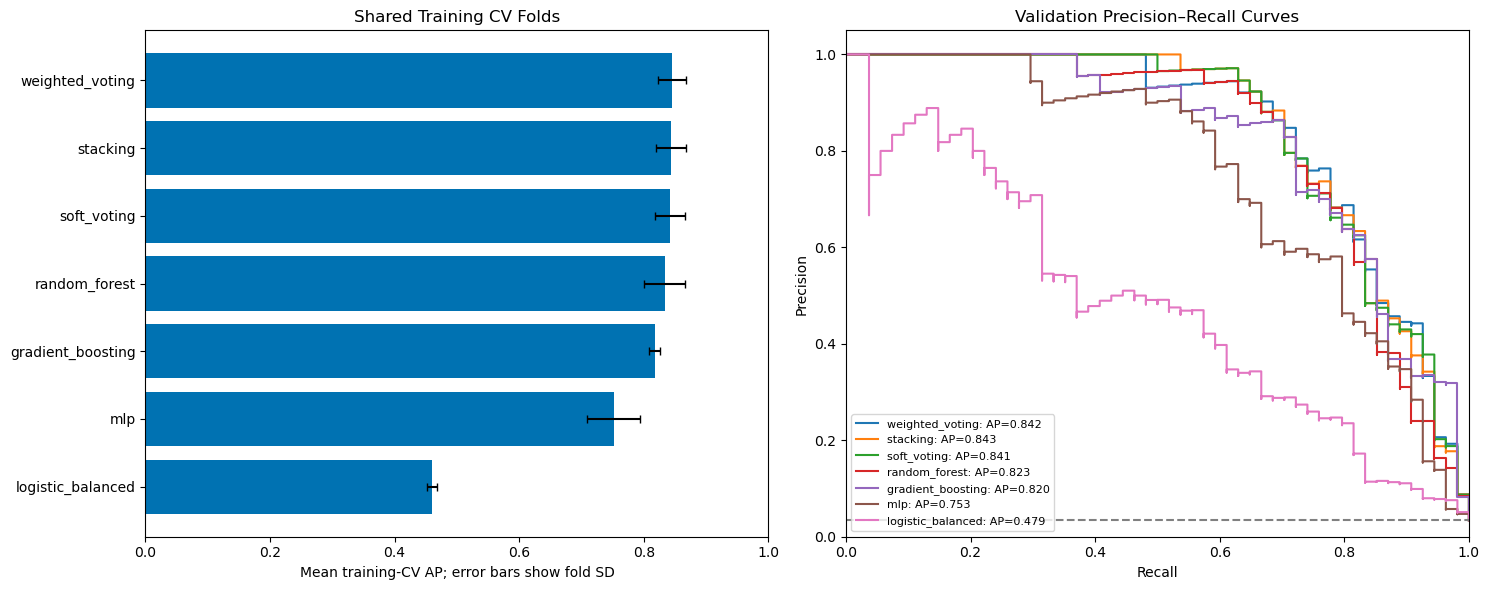

In [6]:
ordered = cv_results.sort_values("average_precision_mean")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(
    ordered.index, ordered["average_precision_mean"],
    xerr=ordered["average_precision_std"], color="#0072B2", capsize=3,
)
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Mean training-CV AP; error bars show fold SD")
axes[0].set_title("Shared Training CV Folds")
for name in ranking.index:
    precision_values, recall_values, _ = precision_recall_curve(y_validation, validation_scores[name])
    ap = validation_results.loc[name, "average_precision"]
    axes[1].step(recall_values, precision_values, where="post", label=f"{name}: AP={ap:.3f}")
axes[1].axhline(y_validation.mean(), color="gray", linestyle="--")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Validation Precision–Recall Curves")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 7. H3 — Exploratory paired comparison

I compare the ensemble with the highest training-CV AP against Random Forest, Gradient Boosting, Logistic Regression, and MLP using their paired, uncalibrated validation scores.

I bootstrap validation observations separately within the failure and no-failure groups, keeping the same sampled rows for each model. This conditions on the observed class counts. I calculate ensemble-minus-comparator AP differences and percentile intervals, using Bonferroni-adjusted tail probabilities for these four comparisons.

These are approximate, exploratory intervals for fixed fitted models. They do not include uncertainty from retraining, prior model/feature selection, or class-prevalence changes. The validation sample has already been explored and used in earlier stages. I do not interpret this as independent confirmation or use different metrics as repeated samples in a Friedman test.

I report whether the intervals support improvement against every specified comparator. I do not automatically mark H3 as confirmed.


Bootstrapping paired AP differences for weighted_voting.
Ensemble superiority is not established across all four specified comparators
This is an exploratory validation comparison; final-test confirmation has not been performed.


,ensemble,comparator,validation_AP_difference,Bonferroni_bootstrap_CI_low,Bonferroni_bootstrap_CI_high,interval_above_zero
0,weighted_voting,random_forest,0.019072,-0.016201,0.065087,False
1,weighted_voting,gradient_boosting,0.021384,-0.024289,0.073935,False
2,weighted_voting,logistic_balanced,0.362629,0.226149,0.490455,True
3,weighted_voting,mlp,0.088487,0.016919,0.177493,True


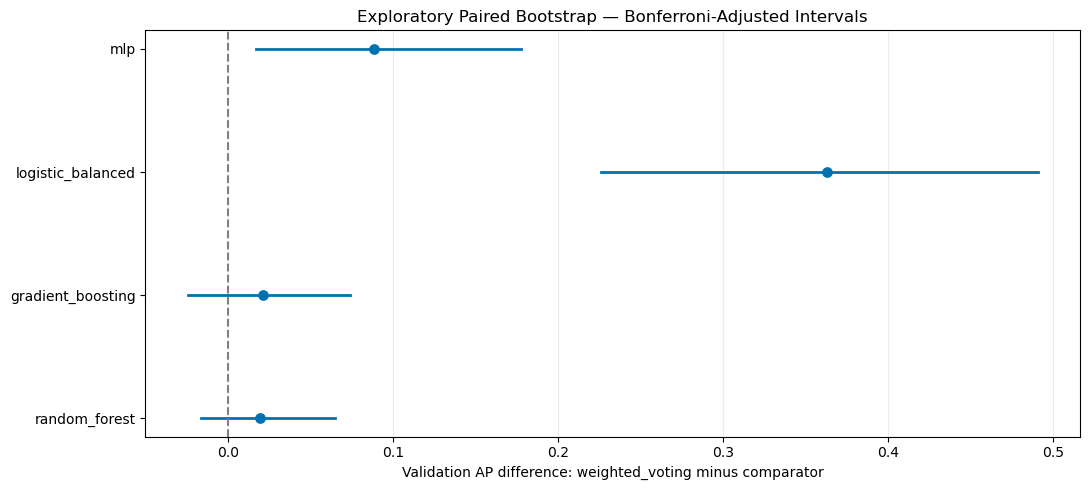

In [7]:
H3_COMPARATORS = ["random_forest", "gradient_boosting", "logistic_balanced", "mlp"]
actual_validation = y_validation.to_numpy()
positive_indices = np.flatnonzero(actual_validation == 1)
negative_indices = np.flatnonzero(actual_validation == 0)
rng = np.random.default_rng(SEED + 70)
delta_draws = np.empty((H3_BOOTSTRAP_REPEATS, len(H3_COMPARATORS)))
ensemble_scores = validation_scores[h3_ensemble_id]

print(f"Bootstrapping paired AP differences for {h3_ensemble_id}.")
with threadpool_limits(limits=1):
    for repeat in range(H3_BOOTSTRAP_REPEATS):
        sampled_indices = np.concatenate([
            rng.choice(positive_indices, size=len(positive_indices), replace=True),
            rng.choice(negative_indices, size=len(negative_indices), replace=True),
        ])
        sampled_y = actual_validation[sampled_indices]
        ensemble_ap = average_precision_score(sampled_y, ensemble_scores[sampled_indices])
        for column, comparator in enumerate(H3_COMPARATORS):
            comparator_ap = average_precision_score(
                sampled_y, validation_scores[comparator][sampled_indices],
            )
            delta_draws[repeat, column] = ensemble_ap - comparator_ap

tail_probability = ALPHA / (2 * len(H3_COMPARATORS))
h3_rows = []
for column, comparator in enumerate(H3_COMPARATORS):
    lower, upper = np.quantile(
        delta_draws[:, column], [tail_probability, 1 - tail_probability],
    )
    observed_delta = (
        validation_results.loc[h3_ensemble_id, "average_precision"]
        - validation_results.loc[comparator, "average_precision"]
    )
    h3_rows.append({
        "ensemble": h3_ensemble_id,
        "comparator": comparator,
        "validation_AP_difference": float(observed_delta),
        "Bonferroni_bootstrap_CI_low": float(lower),
        "Bonferroni_bootstrap_CI_high": float(upper),
        "interval_above_zero": bool(lower > 0),
    })
h3_comparisons = pd.DataFrame(h3_rows)
h3_supported = bool(h3_comparisons["interval_above_zero"].all())
h3_status = (
    "Exploratory interval support for improvement against all four specified comparators"
    if h3_supported else
    "Ensemble superiority is not established across all four specified comparators"
)
display(h3_comparisons)
print(h3_status)
print("This is an exploratory validation comparison; final-test confirmation has not been performed.")

fig, ax = plt.subplots(figsize=(11, 5))
for position, row in h3_comparisons.iterrows():
    ax.plot(
        [row["Bonferroni_bootstrap_CI_low"], row["Bonferroni_bootstrap_CI_high"]],
        [position, position], color="#0072B2", linewidth=2,
    )
    ax.scatter(row["validation_AP_difference"], position, color="#0072B2", s=45, zorder=3)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(np.arange(len(h3_comparisons)))
ax.set_yticklabels(h3_comparisons["comparator"])
ax.set_xlabel(f"Validation AP difference: {h3_ensemble_id} minus comparator")
ax.set_title("Exploratory Paired Bootstrap — Bonferroni-Adjusted Intervals")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "h3_paired_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 8. Assess sigmoid calibration for the CV-selected model

I keep the model family selected by training-CV AP and compare its uncalibrated scores with a sigmoid-calibrated version.

The calibration wrapper obtains out-of-fold training scores from the saved folds, fits its calibration mapping using training outcomes, and fits the underlying model on the full training set. Validation outcomes are not used to fit the mapping. With `ensemble=False`, the calibration wrapper uses one full-training underlying estimator rather than averaging multiple calibrated fold estimators.

I select between these two representations by lower **validation Brier score**. I also report log loss and AP and inspect reliability curves. Brier score measures overall probability prediction error; it is not a pure calibration statistic. The selected option remains provisional because this validation set is used for selection and contains relatively few failures.


Starting training_only_sigmoid_calibration: weighted_voting
Completed training_only_sigmoid_calibration: weighted_voting (81.7s)
Representation chosen by validation Brier score: uncalibrated


,Brier_score,log_loss,average_precision,roc_auc
representation,,,,
uncalibrated,0.011488,0.045157,0.841875,0.982092
sigmoid,0.011768,0.052453,0.841875,0.982092


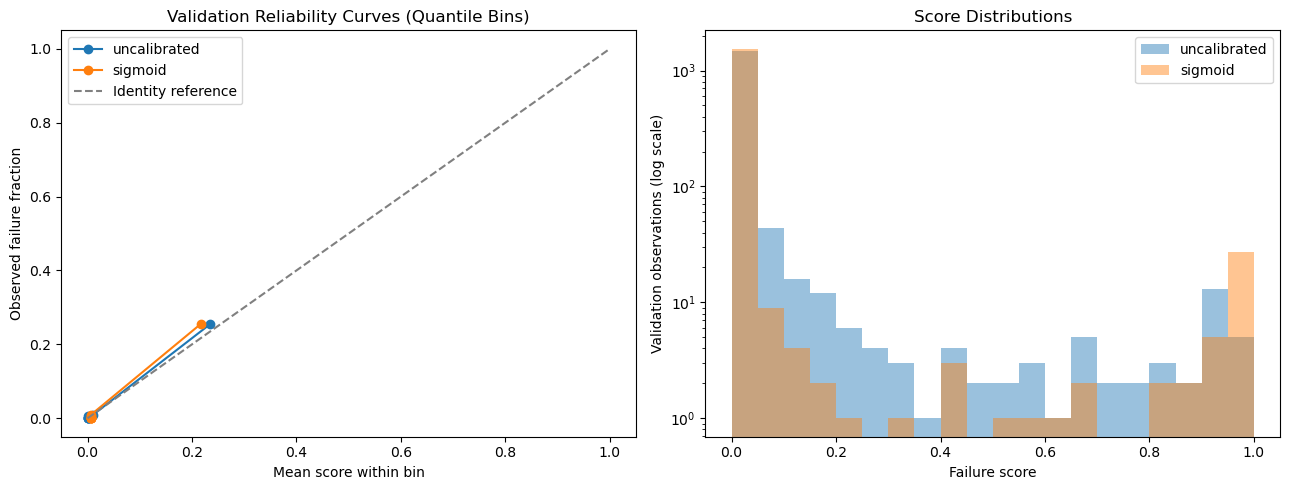

In [8]:
sigmoid_model = CalibratedClassifierCV(
    estimator=clone(candidate_estimators[cv_winner]),
    method="sigmoid", cv=cv_folds, ensemble=False, n_jobs=1,
)
recorded_fit(
    cv_winner, "training_only_sigmoid_calibration",
    lambda: sigmoid_model.fit(X_train, y_train),
)
sigmoid_scores = positive_scores(sigmoid_model, X_validation)

calibration_score_sets = {
    "uncalibrated": uncalibrated_scores,
    "sigmoid": sigmoid_scores,
}
calibration_results = pd.DataFrame([
    {
        "representation": name,
        "Brier_score": float(brier_score_loss(y_validation, scores)),
        "log_loss": float(log_loss(y_validation, scores, labels=[0, 1])),
        "average_precision": float(average_precision_score(y_validation, scores)),
        "roc_auc": float(roc_auc_score(y_validation, scores)),
    }
    for name, scores in calibration_score_sets.items()
]).set_index("representation")
chosen_representation = (
    "sigmoid"
    if calibration_results.loc["sigmoid", "Brier_score"]
       < calibration_results.loc["uncalibrated", "Brier_score"]
    else "uncalibrated"
)
selected_predictor = sigmoid_model if chosen_representation == "sigmoid" else uncalibrated_winner
selected_scores = calibration_score_sets[chosen_representation]
display(calibration_results)
print(f"Representation chosen by validation Brier score: {chosen_representation}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, scores in calibration_score_sets.items():
    observed, predicted = calibration_curve(
        y_validation, scores, n_bins=8, strategy="quantile",
    )
    axes[0].plot(predicted, observed, "o-", label=name)
    axes[1].hist(scores, bins=np.linspace(0, 1, 21), alpha=0.45, label=name)
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Identity reference")
axes[0].set_xlabel("Mean score within bin")
axes[0].set_ylabel("Observed failure fraction")
axes[0].set_title("Validation Reliability Curves (Quantile Bins)")
axes[0].legend()
axes[1].set_xlabel("Failure score")
axes[1].set_ylabel("Validation observations (log scale)")
axes[1].set_yscale("log")
axes[1].set_title("Score Distributions")
axes[1].legend()
plt.tight_layout()
plt.savefig(VISUALS_DIR / "calibration_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 9. Examine validation threshold tradeoffs

I compare 0.5 with the cutoff maximizing validation F1 and illustrative 80%, 90%, and 95% recall scenarios. These targets are not assumed maintenance requirements. They do not guarantee future recall.

I use only validation outcomes for cutoff selection. Tuning results are optimistic relative to independent evaluation, so this notebook does not freeze a business operating policy or assign operational risk tiers.


In [9]:
precision_values, recall_values, thresholds = precision_recall_curve(y_validation, selected_scores)
threshold_grid = pd.DataFrame({
    "threshold": thresholds, "precision": precision_values[:-1], "recall": recall_values[:-1],
})
denominator = (threshold_grid["precision"] + threshold_grid["recall"]).to_numpy()
threshold_grid["f1"] = np.divide(
    2 * threshold_grid["precision"].to_numpy() * threshold_grid["recall"].to_numpy(),
    denominator, out=np.zeros(len(threshold_grid)), where=denominator > 0,
)
demo_row = threshold_grid.sort_values(
    ["f1", "threshold"], ascending=[False, False], kind="stable",
).iloc[0]
demo_threshold = float(demo_row["threshold"])
profile_rows = [
    {"profile": "default_0.5", "recall_target": np.nan,
     **metrics_at_threshold(y_validation, selected_scores, DEFAULT_THRESHOLD)},
    {"profile": "maximum_validation_F1", "recall_target": np.nan,
     **metrics_at_threshold(y_validation, selected_scores, demo_threshold)},
]
for target in RECALL_SCENARIOS:
    feasible = threshold_grid.loc[threshold_grid["recall"] >= target]
    if feasible.empty:
        raise ValueError(f"No observed validation threshold achieves recall {target}.")
    chosen = feasible.sort_values(
        ["precision", "threshold"], ascending=[False, False], kind="stable",
    ).iloc[0]
    measured = metrics_at_threshold(y_validation, selected_scores, float(chosen["threshold"]))
    if measured["recall"] + 1e-12 < target:
        raise RuntimeError("The measured recall constraint was not met.")
    profile_rows.append({
        "profile": f"recall_at_least_{target:.0%}",
        "recall_target": target, **measured,
    })
threshold_profiles = pd.DataFrame(profile_rows).set_index("profile")
display(threshold_profiles.round(4))
print(f"Selected candidate: {cv_winner}; representation: {chosen_representation}")
print(f"Demonstration validation-F1 cutoff: {demo_threshold:.6f}")


Selected candidate: weighted_voting; representation: uncalibrated
Demonstration validation-F1 cutoff: 0.346952


,recall_target,threshold,average_precision,roc_auc,precision,recall,f1,false_negatives,false_positives
profile,,,,,,,,,
default_0.5,NaN,0.5000,0.8419,0.9821,0.9211,0.6481,0.7609,19,3
maximum_validation_F1,NaN,0.3470,0.8419,0.9821,0.8478,0.7222,0.7800,15,7
recall_at_least_80%,0.80,0.1771,0.8419,0.9821,0.6875,0.8148,0.7458,10,20
recall_at_least_90%,0.90,0.0640,0.8419,0.9821,0.4455,0.9074,0.5976,5,61
recall_at_least_95%,0.95,0.0150,0.8419,0.9821,0.2063,0.9630,0.3399,2,200


## 10. Inspect decisions for the selected predictor

I show the 0.5 reference and the validation-F1 demonstration cutoff for the selected score representation. I retain the same model fit; changing the cutoff changes only the decision rule.


              precision    recall  f1-score   support

  No failure       0.99      1.00      0.99      1546
     Failure       0.85      0.72      0.78        54

    accuracy                           0.99      1600
   macro avg       0.92      0.86      0.89      1600
weighted avg       0.99      0.99      0.99      1600



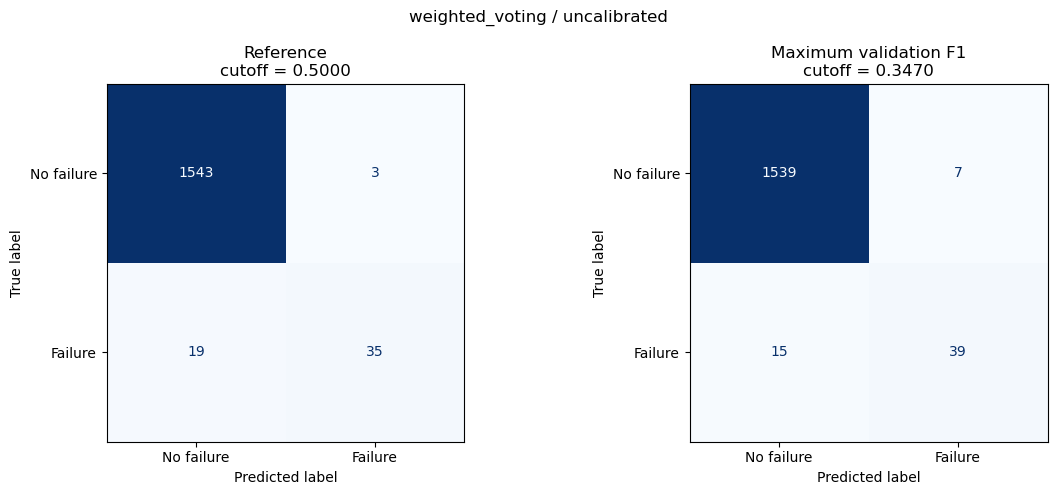

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, cutoff) in zip(axes, [
    ("Reference", DEFAULT_THRESHOLD),
    ("Maximum validation F1", demo_threshold),
]):
    ConfusionMatrixDisplay.from_predictions(
        y_validation, (selected_scores >= cutoff).astype(int),
        labels=[0, 1], display_labels=["No failure", "Failure"],
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(f"{name}\ncutoff = {cutoff:.4f}")
fig.suptitle(f"{cv_winner} / {chosen_representation}")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "selected_threshold_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(classification_report(
    y_validation, (selected_scores >= demo_threshold).astype(int),
    labels=[0, 1], target_names=["No failure", "Failure"], zero_division=0,
))


## 11. Save provisional models and reproducible reports

I save the uncalibrated CV winner, its sigmoid-calibrated version, and the selected representation. I keep models trained on training rows rather than refitting them on validation data.

The saved schema records the required model-input columns. As in notebook 06, the two row-wise formulas are applied before calling the serialized estimator; the reload example shows this explicitly.

The H3 report here records the current exploratory comparison. The hypothesis notebook's earlier pending status remains a historical stage record rather than being overwritten. All final-test evaluation remains outstanding.


In [11]:
warning_table = pd.DataFrame(
    fit_warning_rows, columns=["candidate", "phase", "warning_class", "message"],
)
convergence_warning_count = int(
    warning_table["warning_class"].eq("ConvergenceWarning").sum()
)
input_schema = {
    **baseline_schema,
    "feature_set": FEATURE_SET,
    "model_input_columns": MODEL_INPUT_COLUMNS,
}
model_metadata = {
    "candidate": cv_winner,
    "selected_by": "Highest mean AP on saved training CV folds",
    "score_representation": chosen_representation,
    "representation_selection": "Lower validation Brier score between uncalibrated and training-only sigmoid",
    "feature_set": FEATURE_SET,
    "training_rows": int(len(train_df)),
    "validation_rows": int(len(validation_df)),
    "reserved_final_test_rows": int(len(final_test_udi)),
    "final_test_scored": False,
    "early_EDA_included_final_test_rows": True,
    "refitted_on_validation": False,
    "provisional": True,
    "operating_policy_finalized": False,
    "demonstration_threshold": demo_threshold,
    "threshold_selection": "Maximum validation F1; operating costs are not specified",
    "training_CV_AP_mean_uncalibrated": float(cv_results.loc[cv_winner, "average_precision_mean"]),
    "training_CV_AP_std_uncalibrated": float(cv_results.loc[cv_winner, "average_precision_std"]),
    "validation_AP_selected_representation": float(average_precision_score(y_validation, selected_scores)),
    "validation_Brier_selected_representation": float(
        calibration_results.loc[chosen_representation, "Brier_score"]
    ),
    "calibration_external_validation_complete": False,
    "fit_warning_count": int(len(warning_table)),
    "convergence_warning_count": convergence_warning_count,
    "input_checksums": input_checksums,
    "seed": SEED,
    "voting_weights_RF_GB_MLP": VOTING_WEIGHTS,
    "H3_exploratory_status": h3_status,
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
}

joblib.dump(uncalibrated_winner, MODELS_DIR / "cv_selected_uncalibrated.joblib")
joblib.dump(sigmoid_model, MODELS_DIR / "sigmoid_calibrated.joblib")
joblib.dump(selected_predictor, MODELS_DIR / "selected_predictor.joblib")
(MODELS_DIR / "input_schema.json").write_text(
    json.dumps(input_schema, indent=2, allow_nan=False), encoding="utf-8",
)
(MODELS_DIR / "model_metadata.json").write_text(
    json.dumps(model_metadata, indent=2, allow_nan=False), encoding="utf-8",
)

cv_results.to_csv(REPORTS_DIR / "cross_validation_results.csv")
cv_fold_results.to_csv(REPORTS_DIR / "cross_validation_folds.csv", index=False)
fold_manifest.to_csv(REPORTS_DIR / "training_cv_fold_manifest.csv", index=False)
validation_results.to_csv(REPORTS_DIR / "validation_results.csv")
calibration_results.to_csv(REPORTS_DIR / "calibration_comparison.csv")
threshold_profiles.to_csv(REPORTS_DIR / "threshold_profiles.csv")
threshold_grid.to_csv(REPORTS_DIR / "selected_threshold_grid.csv", index=False)
h3_comparisons.to_csv(REPORTS_DIR / "h3_comparisons.csv", index=False)
warning_table.to_csv(REPORTS_DIR / "fit_warnings.csv", index=False)

predictions = pd.DataFrame({
    "UDI": validation_df["UDI"], "Machine failure": y_validation,
})
for name, scores in validation_scores.items():
    predictions[f"score__{name}"] = scores
predictions.to_csv(REPORTS_DIR / "validation_predictions.csv", index=False)

selected_predictions = validation_df[["UDI", *RAW_FEATURES, "Machine failure"]].copy()
selected_predictions["uncalibrated_winner_score"] = uncalibrated_scores
selected_predictions["sigmoid_score"] = sigmoid_scores
selected_predictions["selected_score"] = selected_scores
selected_predictions["prediction_at_0.5"] = (selected_scores >= DEFAULT_THRESHOLD).astype(int)
selected_predictions["prediction_at_demo_threshold"] = (selected_scores >= demo_threshold).astype(int)
selected_predictions.to_csv(REPORTS_DIR / "selected_validation_predictions.csv", index=False)

h3_report = {
    "ensemble_selected_by_training_CV": h3_ensemble_id,
    "comparators": H3_COMPARATORS,
    "status": h3_status,
    "exploratory": True,
    "independent_confirmation_complete": False,
    "bootstrap_repeats": H3_BOOTSTRAP_REPEATS,
    "sampling": "Paired stratified bootstrap of validation rows; fixed class counts",
    "tail_probability": tail_probability,
    "interval_adjustment": "Bonferroni across four comparator intervals",
    "limitations": [
        "Conditional on fixed fitted models and observed class counts",
        "No retraining or model-selection uncertainty included",
        "Repeatedly explored validation set; not independent confirmation",
    ],
}
(REPORTS_DIR / "h3_status.json").write_text(
    json.dumps(h3_report, indent=2, allow_nan=False), encoding="utf-8",
)
(REPORTS_DIR / "experiment_settings.json").write_text(
    json.dumps({
        "model_metadata": model_metadata,
        "reference_source_ids": reference_source_ids,
        "MLP_parameters": mlp.get_params(),
        "stacking_inner_folds": 3,
        "stacking_MLP_max_iter": 1500,
        "stacking_inner_seed": SEED + 1,
        "calibration": {"method": "sigmoid", "ensemble": False, "CV": "saved training folds"},
        "candidate_parameters": {
            name: {
                key: value for key, value in estimator.get_params(deep=True).items()
                if isinstance(value, (str, int, float, bool, type(None)))
            }
            for name, estimator in candidate_estimators.items()
        },
        "input_files": {
            name: {"relative_path": path.relative_to(PROJECT_ROOT).as_posix(), "sha256": input_checksums[name]}
            for name, path in input_paths.items()
        },
    }, indent=2, allow_nan=False), encoding="utf-8",
)
print(f"Saved models: {MODELS_DIR.relative_to(PROJECT_ROOT)}")
print(f"Saved reports: {REPORTS_DIR.relative_to(PROJECT_ROOT)}")
print(f"Recorded convergence warnings: {convergence_warning_count}")


Saved models: models\ensemble_comparison
Saved reports: reports\ensemble_comparison
Recorded convergence warnings: 0


## 12. Reload and verify the selected predictor

I rebuild the selected feature matrix from raw validation inputs, load the saved estimator and metadata, and compare its scores with those produced before saving. I do not score final-test rows during this verification.


In [12]:
reloaded_predictor = joblib.load(MODELS_DIR / "selected_predictor.joblib")
reloaded_schema = json.loads((MODELS_DIR / "input_schema.json").read_text(encoding="utf-8"))
reloaded_metadata = json.loads((MODELS_DIR / "model_metadata.json").read_text(encoding="utf-8"))
prepared_validation = prepare_features(validation_df)
if prepared_validation.columns.tolist() != reloaded_schema["model_input_columns"]:
    raise ValueError("Prepared inputs differ from the saved schema.")
reloaded_scores = positive_scores(reloaded_predictor, prepared_validation)
np.testing.assert_allclose(reloaded_scores, selected_scores, rtol=0, atol=1e-10)

example = validation_df[["UDI", *RAW_FEATURES]].head(5).copy()
example_scores = positive_scores(reloaded_predictor, prepare_features(example))
example["failure_score"] = example_scores
example["demo_prediction"] = (
    example_scores >= reloaded_metadata["demonstration_threshold"]
).astype(int)
display(example)

for name, path in input_paths.items():
    if sha256(path) != input_checksums[name]:
        raise RuntimeError(f"An input file changed during this run: {name}")
print(f"Provisional CV winner: {cv_winner}")
print(f"Chosen representation: {chosen_representation}")
print(f"Exploratory H3 result: {h3_status}")
print("Verified: saved-model scores match and all input files are unchanged.")
print("Final test remains unscored. The operating policy and independent evaluation are still pending.")


Provisional CV winner: weighted_voting
Chosen representation: uncalibrated
Exploratory H3 result: Ensemble superiority is not established across all four specified comparators
Verified: saved-model scores match and all input files are unchanged.
Final test remains unscored. The operating policy and independent evaluation are still pending.


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type,failure_score,demo_prediction
0,8,298.1,308.6,1527,40.2,16,L,0.000766,0
1,11,298.4,308.9,1782,23.9,24,H,0.000766,0
2,15,298.6,309.2,2035,19.6,40,L,0.000929,0
3,29,299.1,309.4,1439,44.2,82,L,0.000766,0
4,34,298.9,309.3,1665,32.5,93,L,0.000848,0


## Interpretation and next steps

I use the measured results to judge whether model combination improved ranking performance. An ensemble is not automatically preferable to the baseline, and a small score difference is not proof of superiority.

The MLP is one neural-network configuration, not a claim about all deep-learning methods. Recorded convergence warnings need investigation before relying on affected models. Calibration and threshold results are validation-based choices rather than externally verified failure-risk guarantees.

Next, I can examine feature explanations and prediction errors for the selected provisional model. Before final evaluation, I will settle the model, calibration choice, and operating objective. I will then evaluate the frozen approach on the reserved test rows, acknowledging their earlier EDA exposure.
